In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import joblib

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV,
    RandomizedSearchCV,
    cross_validate
)

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.feature_selection import SelectKBest, f_classif

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    BaggingClassifier,
    RandomForestClassifier,
    GradientBoostingClassifier,
    VotingClassifier
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

In [4]:
df = pd.read_csv("../data/telco_churn.csv")

print(df.shape)
print(df.head())
print(df.info())
print(df.describe(include="all"))
print(df.isnull().sum())
print(df["Churn"].value_counts())
print(df["Churn"].value_counts(normalize=True))

(7043, 21)
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Co

In [6]:
# Clean the common TotalCharges formatting issue:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].replace(r"^\s*$", np.nan, regex=True),
    errors="coerce"
)

In [7]:
# Convert the target:
df["Churn"] = df["Churn"].map({
    "Yes": 1,
    "No": 0
})

In [9]:
# Remove rows with a missing target and exclude the customer identifier:
df = df.dropna(subset=["Churn"])

X = df.drop(columns=["Churn", "customerID"])
y = df["Churn"].astype(int)

In [11]:
# split before learning from the data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [12]:
def evaluate_model(model, X_test, y_test):
    predictions = model.predict(X_test)

    probabilities = None
    if hasattr(model, "predict_proba"):
        probabilities = model.predict_proba(X_test)[:, 1]

    print("Accuracy:",
          accuracy_score(y_test, predictions))

    print("Precision:",
          precision_score(y_test, predictions, zero_division=0))

    print("Recall:",
          recall_score(y_test, predictions, zero_division=0))

    print("F1:",
          f1_score(y_test, predictions, zero_division=0))

    if probabilities is not None:
        print("ROC-AUC:",
              roc_auc_score(y_test, probabilities))

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test, predictions))

    print("\nClassification Report:")
    print(classification_report(
        y_test, predictions, zero_division=0
    ))

In [17]:
# Feature 1: Tenure Group
# Create customer lifecycle groups.
df["tenure_group"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 100],
    labels=[
        "0-12 months",
        "13-24 months",
        "25-48 months",
        "49+ months"
    ]
)

In [18]:
# Feature 2: Average Monthly Spend
# Average Monthly Spend
df["avg_monthly_spend"] = (
    df["TotalCharges"] / df["tenure"].replace(0, np.nan)
)

In [19]:
# Feature 3: Lifetime Value Proxy

# Create a simple customer value proxy:

df["lifetime_value_proxy"] = (
    df["MonthlyCharges"] * df["tenure"]
)

In [20]:
# Feature 4: Service Count

# Count how many services the customer has subscribed to.

service_columns = [
    "PhoneService",
    "MultipleLines",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]

df["service_count"] = (
    df[service_columns]
    .eq("Yes")
    .sum(axis=1)
)

In [21]:
# Feature 5: Support or Security Indicator

df["has_support_or_security"] = (
    (df["OnlineSecurity"] == "Yes") |
    (df["TechSupport"] == "Yes")
).astype(int)

In [22]:
# Feature 6: Monthly Charge per Service

df["monthly_charge_per_service"] = (
    df["MonthlyCharges"] /
    df["service_count"].replace(0, np.nan)
)

In [23]:
# Feature 7: Long-Tenure Indicator

df["is_long_tenure"] = (
    df["tenure"] >= 24
).astype(int)

# 7.3 Compare baseline and engineered models

Use Logistic Regression for a controlled comparison.

The baseline uses original features. The engineered model uses original features plus the new features.

Both models must use the same train/test split and preprocessing strategy.

In [25]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Identify numerical and categorical columns
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object", "str"]).columns.tolist()

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

In [26]:
# Example baseline:

baseline_model = Pipeline([
    ("preprocess", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced"
    ))
])

In [32]:
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Create a copy of the training data
X_train_engineered = X_train.copy()

X_test_engineered = X_test.copy()

X_test_engineered["tenure_group"] = pd.cut(
    X_test_engineered["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0-12", "13-24", "25-48", "49-72"]
)

# Add an engineered feature
X_train_engineered["tenure_group"] = pd.cut(
    X_train_engineered["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0-12", "13-24", "25-48", "49-72"]
)

In [29]:
# Identify numerical and categorical columns
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object", "str"]).columns.tolist()

# Add tenure_group to categorical features
if "tenure_group" not in categorical_features:
    categorical_features.append("tenure_group")

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

engineered_preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

In [30]:
#Example engineered model:

engineered_model = Pipeline([
    ("preprocess", engineered_preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced"
    ))
])

In [33]:
# Fit and evaluate:

baseline_model.fit(X_train, y_train)
engineered_model.fit(X_train_engineered, y_train)

evaluate_model(baseline_model, X_test, y_test)
evaluate_model(engineered_model, X_test_engineered, y_test)

Accuracy: 0.7381121362668559
Precision: 0.504302925989673
Recall: 0.7834224598930482
F1: 0.6136125654450262
ROC-AUC: 0.8412978893797307

Confusion Matrix:
[[747 288]
 [ 81 293]]

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1035
           1       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409

Accuracy: 0.7324343506032647
Precision: 0.49747899159663866
Recall: 0.7914438502673797
F1: 0.6109391124871001
ROC-AUC: 0.8420238187501614

Confusion Matrix:
[[736 299]
 [ 78 296]]

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.71      0.80      1035
           1       0.50      0.79      0.61       374

    accuracy                           0.73      1409
   macro avg       0.70      0.75      0.70      

# 8.2 Correlation analysis

Correlation measures the strength and direction of a linear relationship between two numerical variables.

Calculate correlations:

In [34]:
numeric_df = X_train.select_dtypes(
    include=["number", "bool"]
)

correlation_matrix = numeric_df.corr()

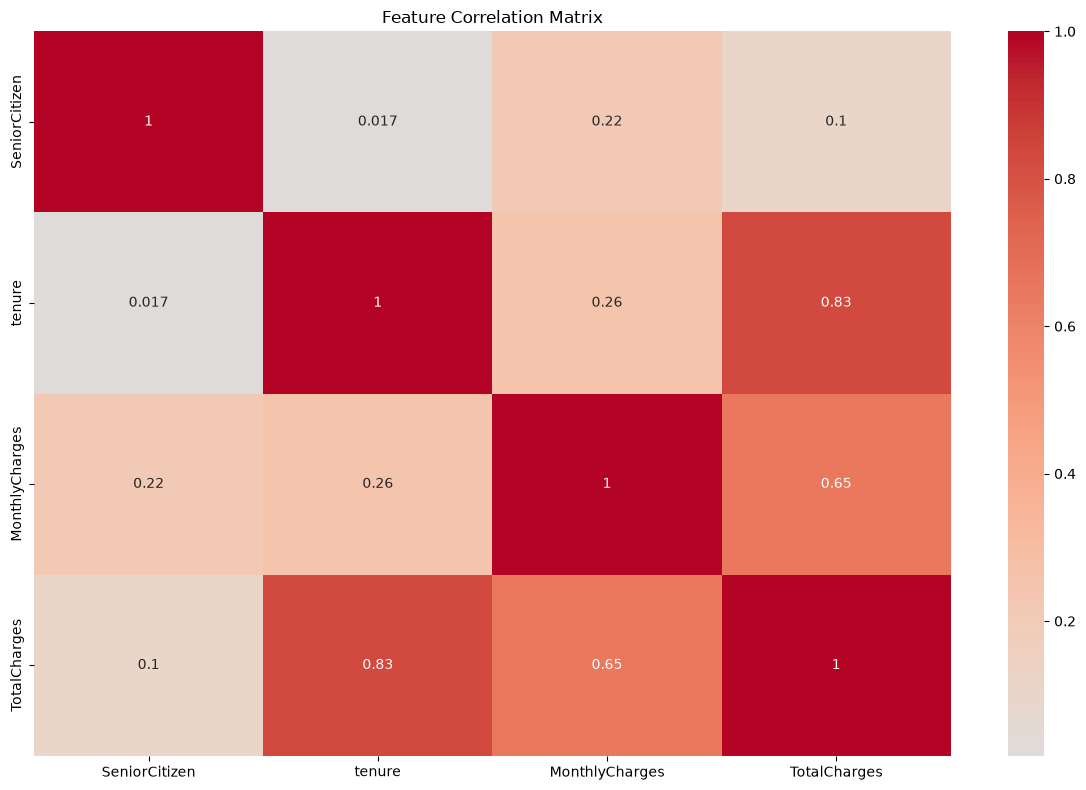

In [35]:
# Visualize:

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    center=0
)

plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

Interpretation:

Close to +1: strong positive linear association.

Close to -1: strong negative linear association.

Close to 0: weak linear association.

You may use an absolute correlation threshold such as 0.85 to identify pairs for further review.

Do not automatically delete a feature simply because it is correlated with another feature. Two correlated features may still contain useful information.

Correlation does not establish causation.

# 8.3 SelectKBest

SelectKBest selects the top K features according to a statistical scoring function.

For classification with numerical transformed features, one common choice is f_classif.

Example:

In [36]:
from sklearn.feature_selection import SelectKBest, f_classif

selector = SelectKBest(
    score_func=f_classif,
    k=20
)

In [37]:
#  proper model pipeline places feature selection after preprocessing:

model = Pipeline([
    ("preprocess", preprocessor),
    ("selection", SelectKBest(
        score_func=f_classif,
        k=20
    )),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced"
    ))
])

# 8.4 Compare models

Compare:

Preprocessing + Logistic Regression.

Preprocessing + SelectKBest + Logistic Regression.

Try different values of K, such as:

k_values = [10, 15, 20, 30]